In [1]:
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
import time
import numpy as np
import pandas as pd

# bdopt: building design optimisation with EnergyPlus
import bdopt
from bdopt import viz
from bdopt import load_idf                      # read the model (.idf)
from bdopt import (
    Parameter,
    RangeParameter,
    CategoryParameter,
    FieldSelector,
    MultiSelector,
    MeterReader,
    VariableReader,
    Problem,
    EnergyPlusEvaluator,
)
from bdopt.sampling import lhs                  # Latin hypercube sampling
from bdopt.adaptive import AdaptiveSampler      # adaptive sampling
from bdopt.surrogate import GPSurrogate, MLPSurrogate, AutoSurrogate
from bdopt.optimize import nsga2                # multi-objective optimisation (NSGA-II)

# Plots
import matplotlib.pyplot as plt

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import sqrt

print('bdopt', bdopt.__version__)

bdopt 0.2.0


In [2]:
# Uploaded model and weather file (written by the platform at upload)
idf = load_idf(r"../uploads/Office_IDF_3.idf")
epw_file = r"../uploads/PARIS_FR-hour.epw"


In [3]:
# Define the problem: what to vary (parameters), what to improve (objectives), how EnergyPlus is run.
# Written by the platform from the problem you defined; change it as you like.
# It needs two names from the cell above: idf (the model, bdopt.load_idf) and epw_file (the weather file).
# Every selector is checked against the model when the evaluator is created, with suggestions for a typo.
from bdopt import (
    CategoryParameter, EnergyPlusEvaluator, FieldSelector, Parameter, Problem, RangeParameter,
)
from bdopt.sampling import lhs

# 8 parameters = 8 columns of `samples`, however many objects each one writes.
parameters = []

# External walls conductivity _InsulationEX_.01
#   writes 1 Material object, field "Conductivity"
external_walls_conductivity_sel = FieldSelector(
    class_name="Material",
    object_name="_InsulationEX_.01",
    field_name="Conductivity",
)
parameters.append(Parameter(
    selector=external_walls_conductivity_sel,
    value_descriptor=RangeParameter(0.017, 0.051),
    name="External walls conductivity _InsulationEX_.01",
))

# Roof conductivity _InsulationEX_Roof_.01
#   writes 1 Material object, field "Conductivity"
roof_conductivity_insulation_sel = FieldSelector(
    class_name="Material",
    object_name="_InsulationEX_Roof_.01",
    field_name="Conductivity",
)
parameters.append(Parameter(
    selector=roof_conductivity_insulation_sel,
    value_descriptor=RangeParameter(0.02, 0.06),
    name="Roof conductivity _InsulationEX_Roof_.01",
))

# External walls thickness _InsulationEX_.01
#   writes 1 Material object, field "Thickness"
external_walls_thickness_ins_sel = FieldSelector(
    class_name="Material",
    object_name="_InsulationEX_.01",
    field_name="Thickness",
)
parameters.append(Parameter(
    selector=external_walls_thickness_ins_sel,
    value_descriptor=RangeParameter(0.02, 0.3),
    name="External walls thickness _InsulationEX_.01",
))

# Roof thickness _InsulationEX_Roof_.01
#   writes 1 Material object, field "Thickness"
roof_thickness_insulationex_sel = FieldSelector(
    class_name="Material",
    object_name="_InsulationEX_Roof_.01",
    field_name="Thickness",
)
parameters.append(Parameter(
    selector=roof_thickness_insulationex_sel,
    value_descriptor=RangeParameter(0.02, 0.3),
    name="Roof thickness _InsulationEX_Roof_.01",
))

# People Activity Level Schedule Name
#   writes every People object, field "Activity Level Schedule Name"
#   The column holds the option itself; problem.json numbered the options:
#     1 = Activity Schedule 285, 2 = Activity Schedule 292, 3 = Activity Schedule 299,
#     4 = Activity Schedule 306, 5 = Activity Schedule 313
people_activity_level_schedu_sel = FieldSelector(
    class_name="People",
    object_name="*",
    field_name="Activity Level Schedule Name",
)
people_activity_level_schedu_options = CategoryParameter([
    "Activity Schedule 285", "Activity Schedule 292", "Activity Schedule 299",
    "Activity Schedule 306", "Activity Schedule 313",
])
parameters.append(Parameter(
    selector=people_activity_level_schedu_sel,
    value_descriptor=people_activity_level_schedu_options,
    name="People Activity Level Schedule Name",
))

# ZoneVentilation:DesignFlowRate Air Changes per Hour
#   writes every ZoneVentilation:DesignFlowRate object, field "Air Changes per Hour"
zoneventilation_designflowra_sel = FieldSelector(
    class_name="ZoneVentilation:DesignFlowRate",
    object_name="*",
    field_name="Air Changes per Hour",
)
parameters.append(Parameter(
    selector=zoneventilation_designflowra_sel,
    value_descriptor=RangeParameter(0.5, 1.5),
    name="ZoneVentilation:DesignFlowRate Air Changes per Hour",
))

# ZoneInfiltration:DesignFlowRate Air Changes per Hour
#   writes every ZoneInfiltration:DesignFlowRate object, field "Air Changes per Hour"
zoneinfiltration_designflowr_sel = FieldSelector(
    class_name="ZoneInfiltration:DesignFlowRate",
    object_name="*",
    field_name="Air Changes per Hour",
)
parameters.append(Parameter(
    selector=zoneinfiltration_designflowr_sel,
    value_descriptor=RangeParameter(0.05, 0.15),
    name="ZoneInfiltration:DesignFlowRate Air Changes per Hour",
))

# ZoneHVAC:IdealLoadsAirSystem Cooling Availability Schedule Name
#   writes every ZoneHVAC:IdealLoadsAirSystem object, field "Cooling Availability Schedule Name"
#   The column holds the option itself; problem.json numbered the options:
#     1 = Block1:OfficeXSWX1f Cooling Availability Sch,
#     2 = Block1:OfficeXSEX1f Cooling Availability Sch,
#     3 = Block1:OfficeXNWX1f Cooling Availability Sch,
#     4 = Block1:OfficeXNEX1f Cooling Availability Sch,
#     5 = Block1:CorridorX1f Cooling Availability Sch
zonehvac_idealloadsairsystem_sel = FieldSelector(
    class_name="ZoneHVAC:IdealLoadsAirSystem",
    object_name="*",
    field_name="Cooling Availability Schedule Name",
)
zonehvac_idealloadsairsystem_options = CategoryParameter([
    "Block1:OfficeXSWX1f Cooling Availability Sch", "Block1:OfficeXSEX1f Cooling Availability Sch",
    "Block1:OfficeXNWX1f Cooling Availability Sch", "Block1:OfficeXNEX1f Cooling Availability Sch",
    "Block1:CorridorX1f Cooling Availability Sch",
])
parameters.append(Parameter(
    selector=zonehvac_idealloadsairsystem_sel,
    value_descriptor=zonehvac_idealloadsairsystem_options,
    name="ZoneHVAC:IdealLoadsAirSystem Cooling Availability Schedule Name",
))

# Objectives: meters, summed over the run period, in joules.
# A plain name is minimised; MeterReader(name, direction="max") maximises.
objectives = [
    "Electricity:Facility",
    "DistrictCooling:Facility",
    "DistrictHeating:Facility",
]
problem = Problem(parameters, objectives)

# EnergyPlus writes every Output:Variable the model asks for into its results database, and a detailed model
# asks for hundreds. The objectives are meters, which the evaluator requests by itself, so none of those
# variables is needed: they are removed from the copy that is simulated (idf itself is left as it is).
# An objective that reads a variable, e.g. VariableReader, makes the evaluator request that variable itself.
sim_idf = idf.copy()
sim_idf.remove(sim_idf.by_class("Output:Variable"))
evaluator = EnergyPlusEvaluator(
    problem, sim_idf, epw_file,
    out_dir="/tmp/bdopt_runs",  # run folders on the container's own disk: much faster than a shared folder
    err_dir="outputdir",        # a run that fails is kept here, with EnergyPlus' error file
    processes=2,                # EnergyPlus runs in parallel
)

samples = lhs(problem, 20)  # 20 Latin hypercube samples: a row per design, a column per parameter
# lhs(problem, 20, seed=1) gives the same samples every time, and runs already done are not repeated (the cache lives in /tmp/bdopt_runs, so until the container is recreated).

In [4]:
print(samples)

    External walls conductivity _InsulationEX_.01  \
0                                        0.039145   
1                                        0.023644   
2                                        0.025313   
3                                        0.032637   
4                                        0.019265   
5                                        0.050755   
6                                        0.034444   
7                                        0.018167   
8                                        0.045738   
9                                        0.042026   
10                                       0.042821   
11                                       0.049176   
12                                       0.037933   
13                                       0.046996   
14                                       0.021354   
15                                       0.037367   
16                                       0.030109   
17                                       0.027

In [5]:
results = evaluator.evaluate(samples)

In [6]:
print(results)

    Electricity:Facility  DistrictCooling:Facility  DistrictHeating:Facility
0           5.394659e+10              1.685737e+10              7.891899e+09
1           5.394659e+10              1.769704e+10              6.311190e+09
2           5.394659e+10              1.877014e+10              3.542101e+09
3           5.394659e+10              1.620964e+10              2.598591e+09
4           5.394659e+10              1.619335e+10              2.485516e+09
5           5.394659e+10              1.790206e+10              3.908569e+09
6           5.394659e+10              1.783894e+10              7.077986e+09
7           5.394659e+10              1.996101e+10              3.154730e+09
8           5.394659e+10              2.093114e+10              2.552718e+10
9           5.394659e+10              1.873231e+10              2.430204e+09
10          5.394659e+10              1.647427e+10              2.950342e+09
11          5.394659e+10              2.025846e+10              5.680759e+09

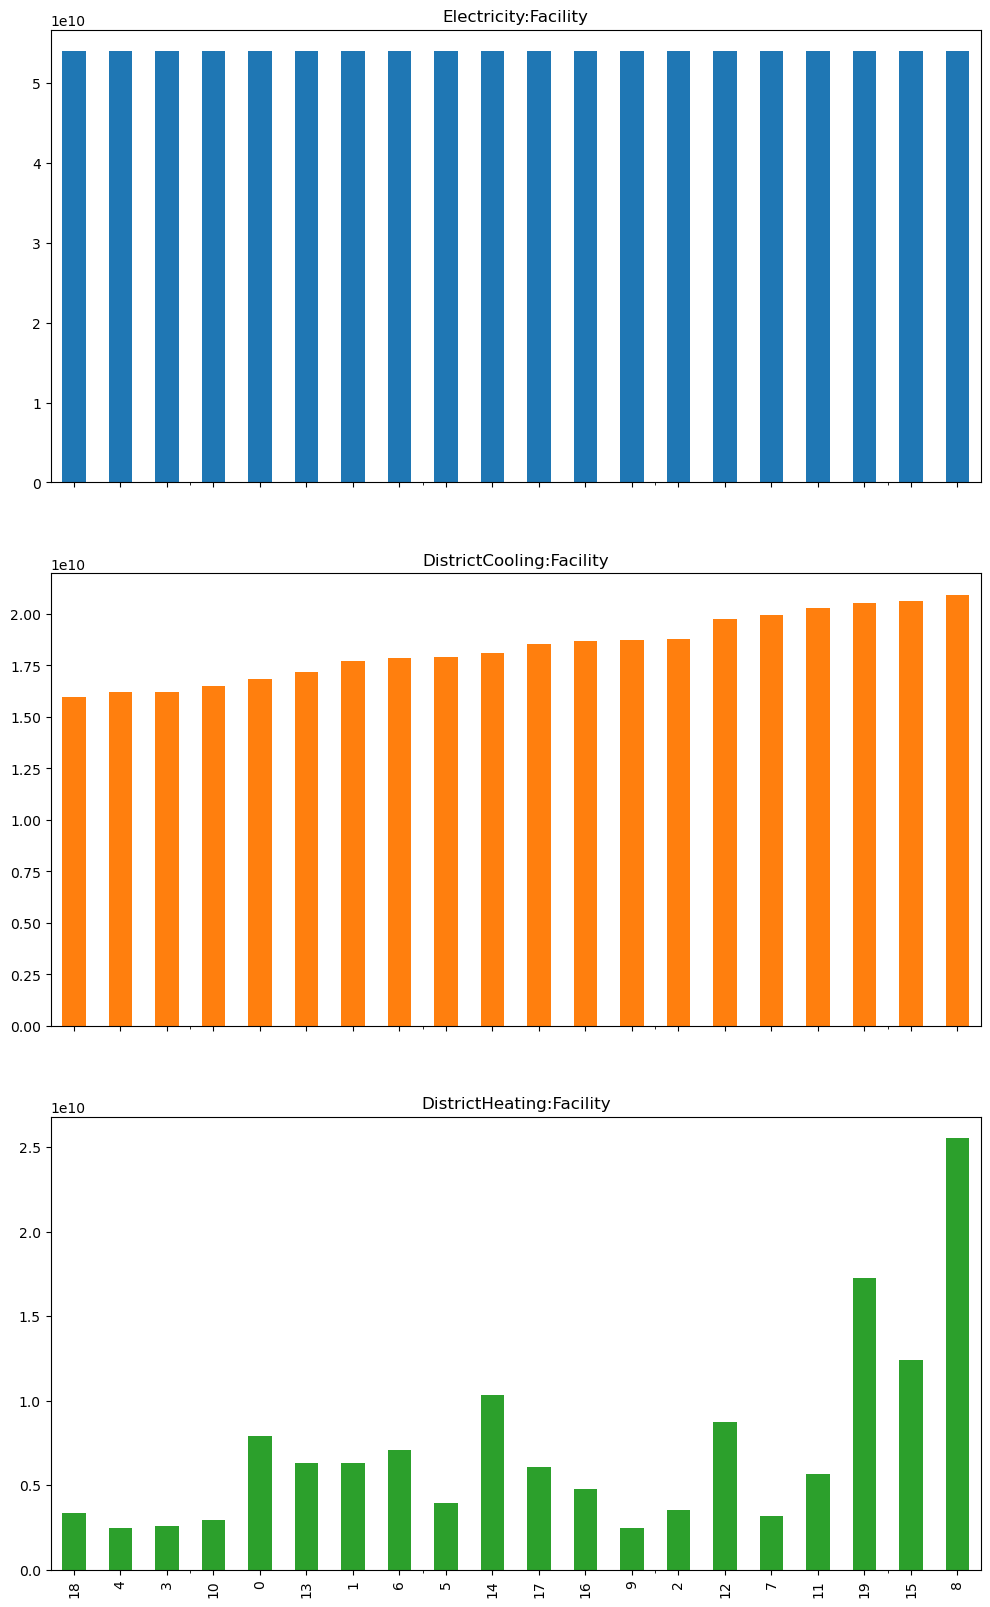

In [7]:
outputs = results.sort_values(by=objectives[1])
ax = outputs.plot.bar(subplots=True, legend=None, figsize=(12, 20))


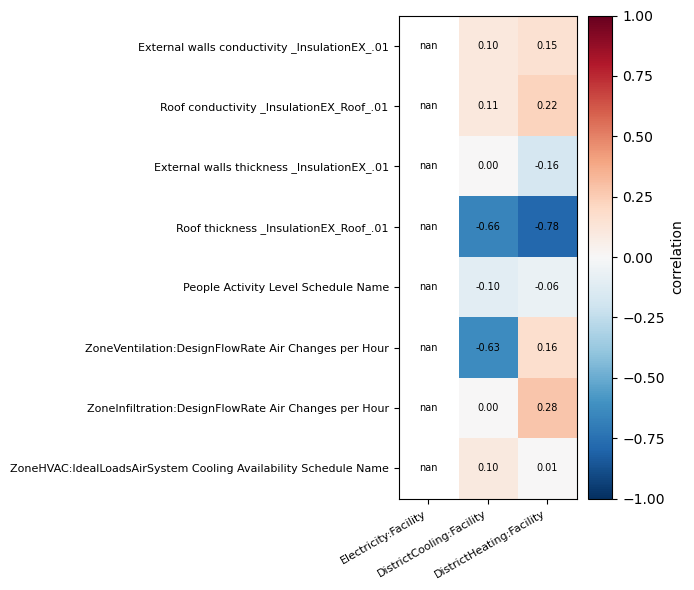

In [8]:
outputs_combined = pd.concat([samples, results], axis=1)
viz.correlation_heatmap(outputs_combined, problem)
plt.show()